In [1]:
#import libraries 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate
import sklearn
import sklearn.metrics as metrics

#will likely use XGBoost

In [2]:
#load dataset and define variable names

varNames = ["id", "Name", "Gender", "Age", "City", "Working Professional or Student", 
            "Profession", "Academic Pressure", "Work Pressure", "CGPA", "Study Satisfaction",	
            "Job Satisfaction",	"Sleep Duration", "Dietary Habits",	"Degree", "Have you ever had suicidal thoughts ?",
            "Work/Study Hours",	"Financial Stress",	"Family History of Mental Illness",	"Depression"]

#needs to run in MentalHealthProject directory
df=pd.read_csv("train.csv", names=varNames, header=0)
df_Test=pd.read_csv("test.csv", names=varNames[:-1], header=0) #test dataset does not have the target variable

In [3]:
print(f"Training dataset shape: {df.shape}")
print(f"Test dataset shape: {df_Test.shape}")
print(f"Combined Shape: ({df.shape[0] + df_Test.shape[0]}, {df.shape[1]})")

Training dataset shape: (140700, 20)
Test dataset shape: (93800, 19)
Combined Shape: (234500, 20)


In [4]:
# print the first couple rows of the training dataset
df.head(5)

,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,Aaradhya,Female,49.0,Ludhiana,Working Professional,Chef,NaN,5.0,NaN,NaN,2.0,More than 8 hours,Healthy,BHM,No,1.0,2.0,No,0
1,1,Vivan,Male,26.0,Varanasi,Working Professional,Teacher,NaN,4.0,NaN,NaN,3.0,Less than 5 hours,Unhealthy,LLB,Yes,7.0,3.0,No,1
2,2,Yuvraj,Male,33.0,Visakhapatnam,Student,NaN,5.0,NaN,8.97,2.0,NaN,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
3,3,Yuvraj,Male,22.0,Mumbai,Working Professional,Teacher,NaN,5.0,NaN,NaN,1.0,Less than 5 hours,Moderate,BBA,Yes,10.0,1.0,Yes,1
4,4,Rhea,Female,30.0,Kanpur,Working Professional,Business Analyst,NaN,1.0,NaN,NaN,1.0,5-6 hours,Unhealthy,BBA,Yes,9.0,4.0,Yes,0


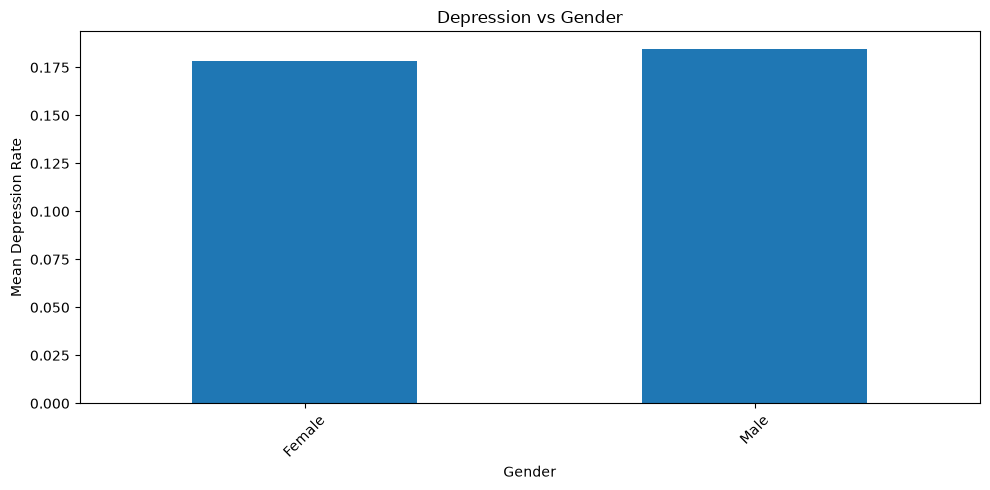

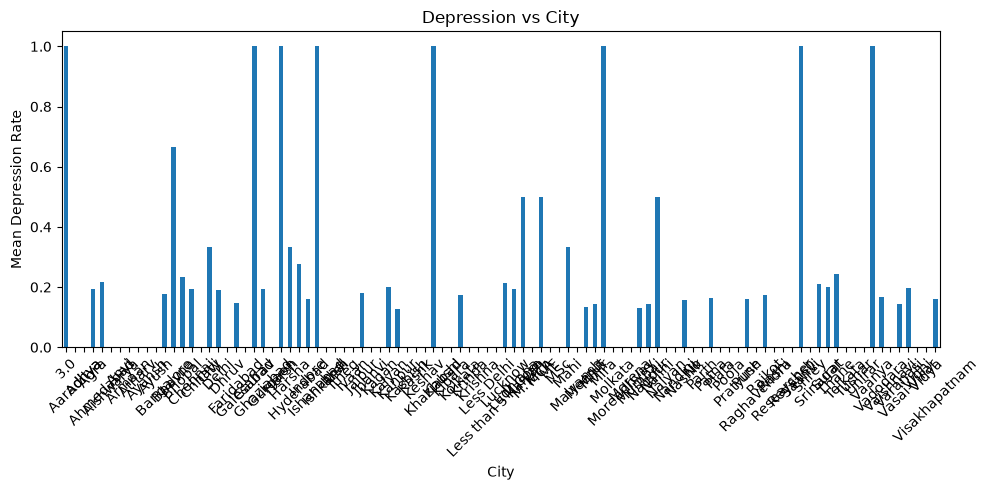

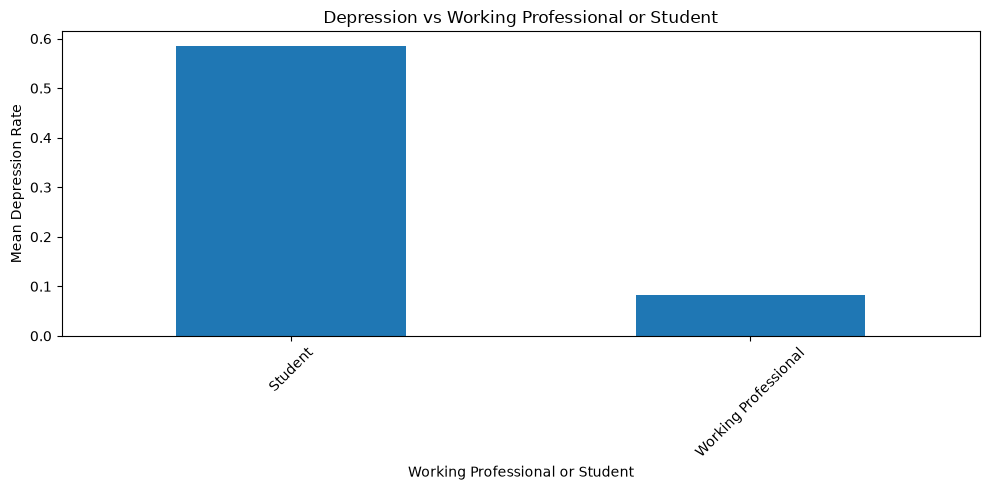

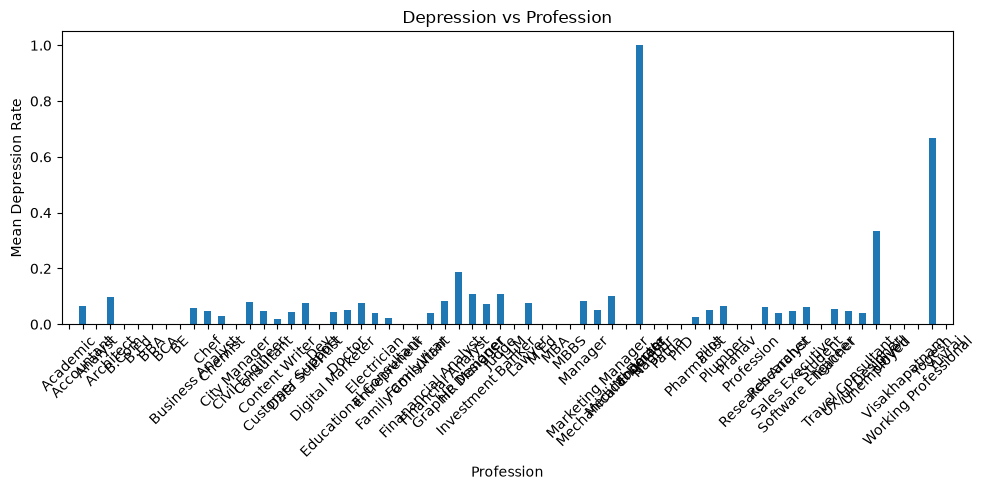

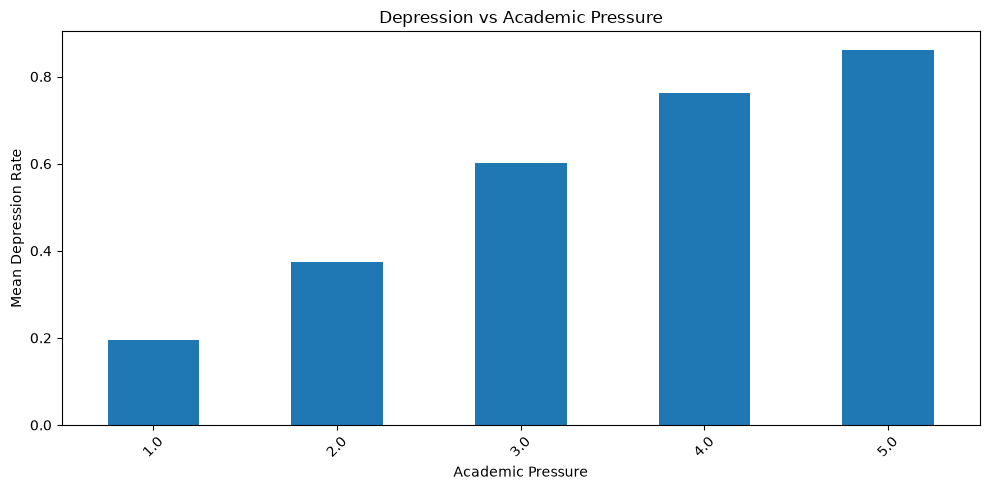

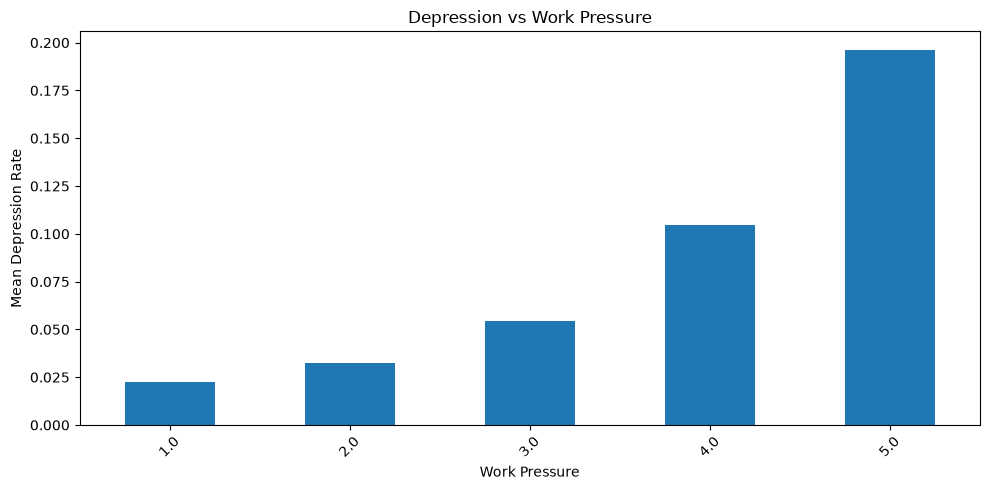

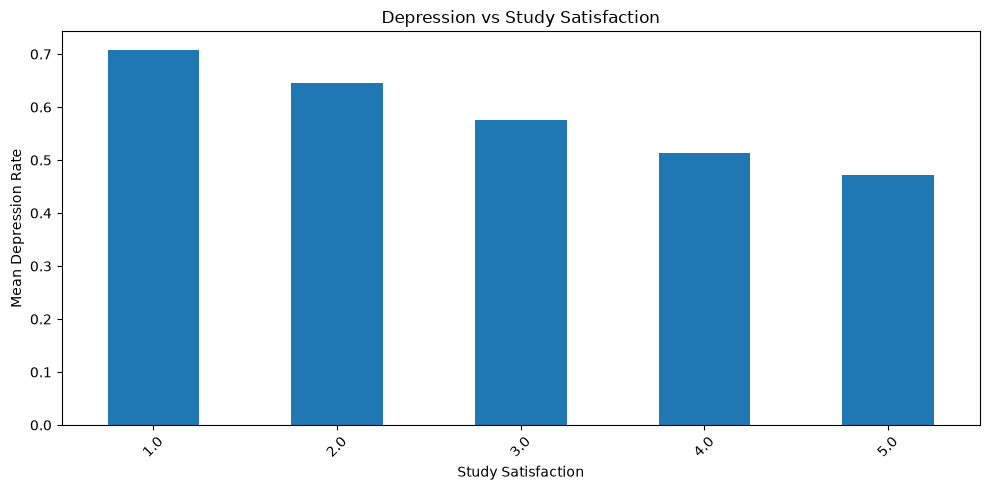

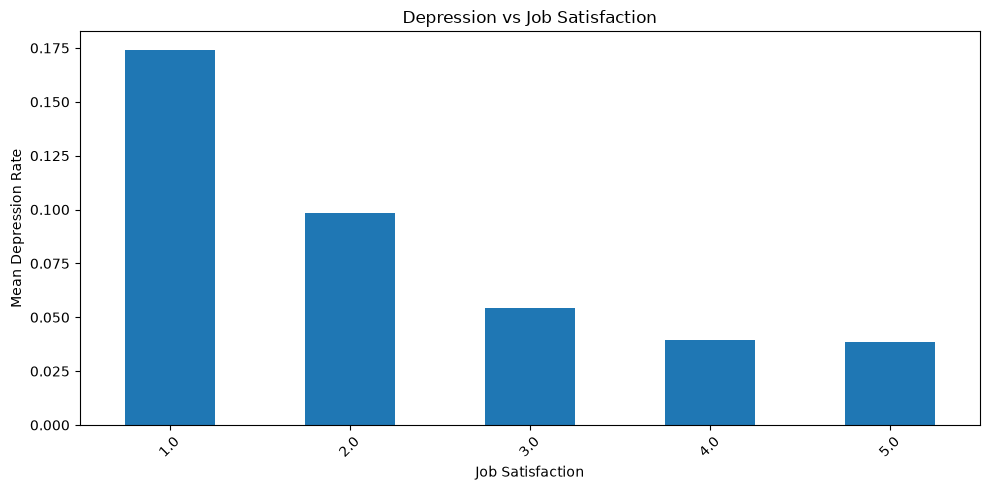

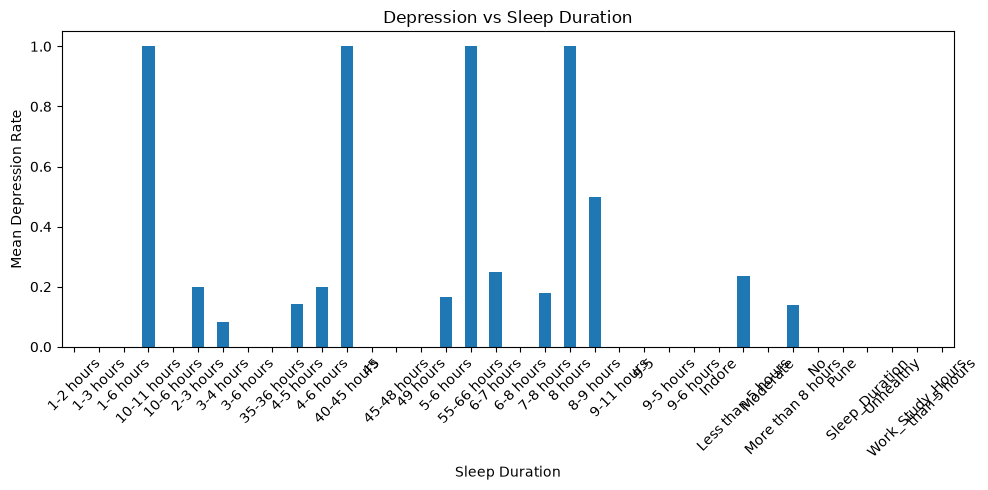

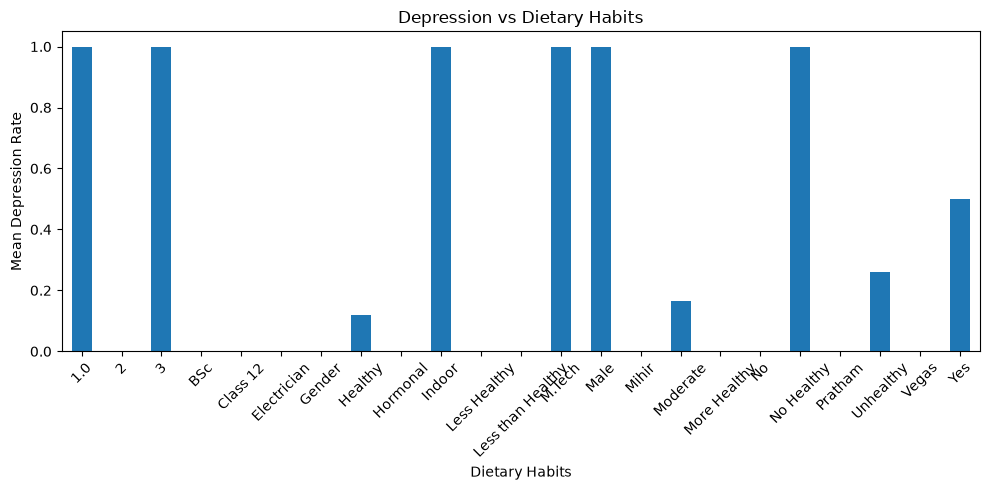

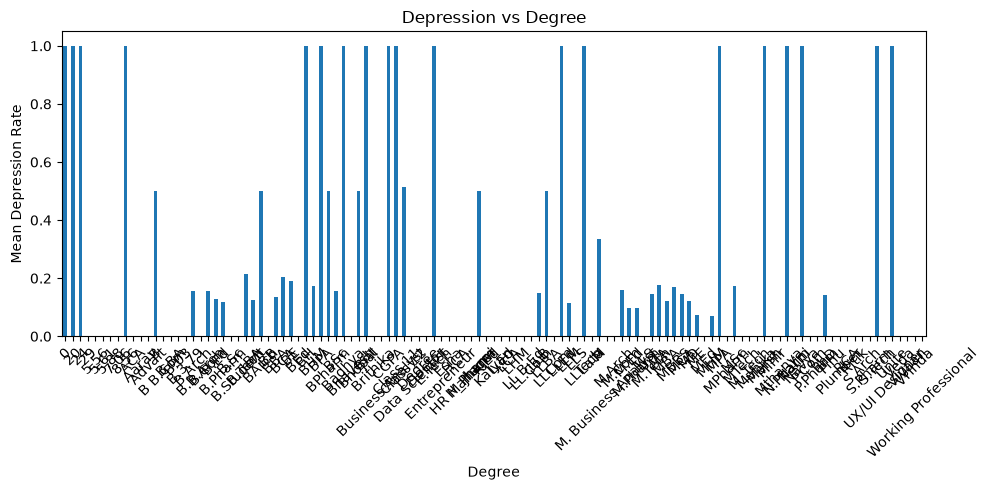

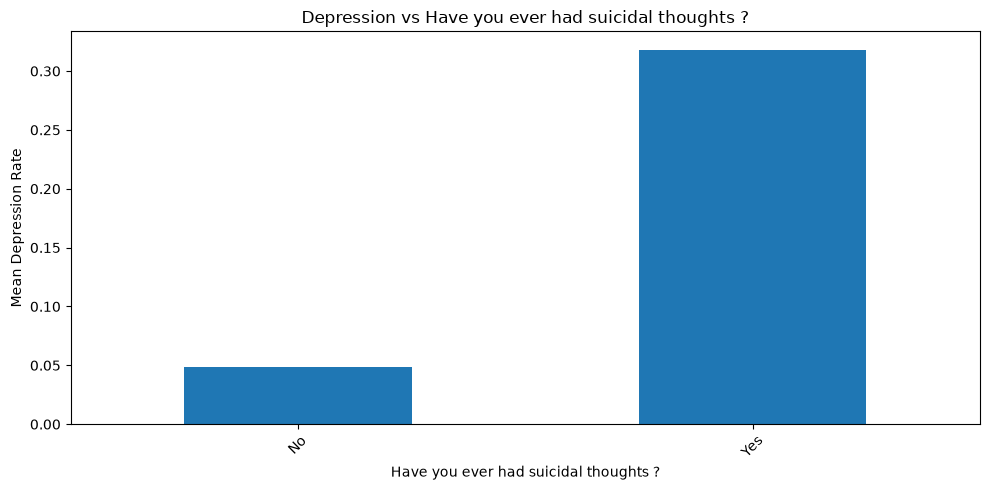

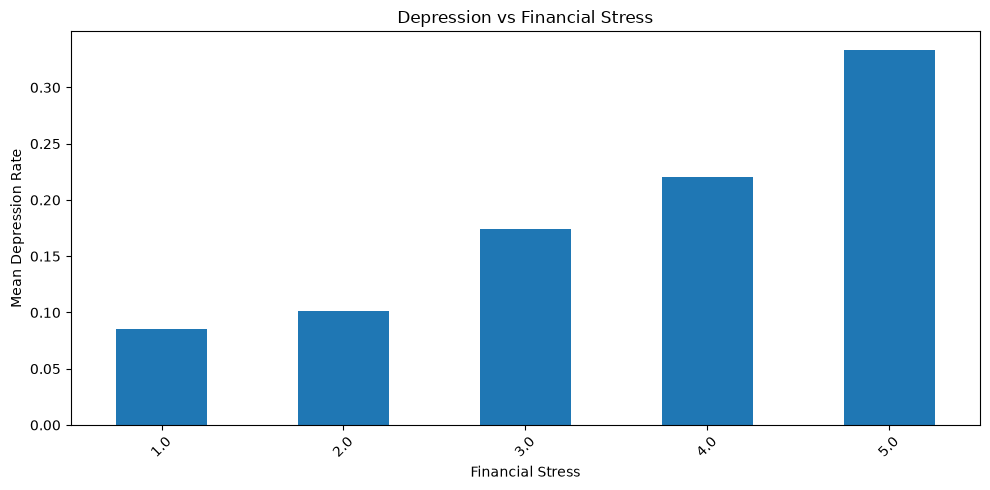

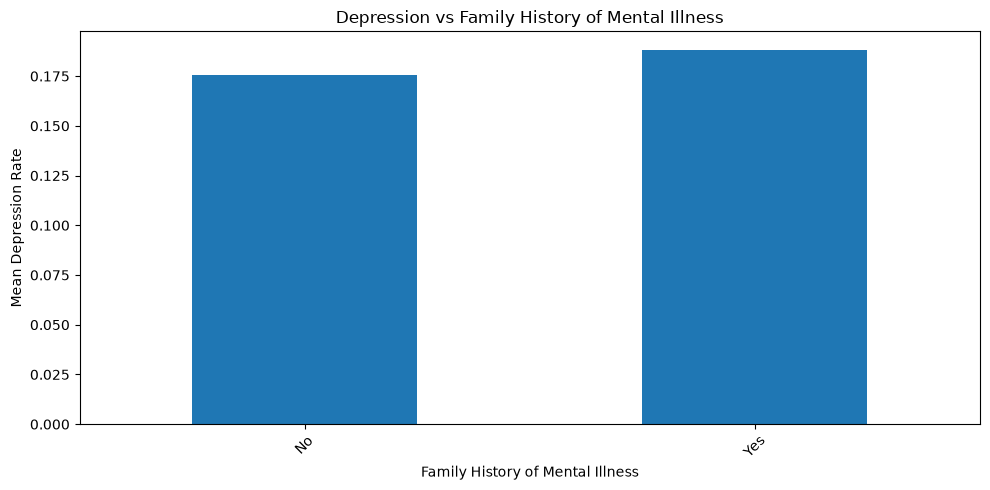

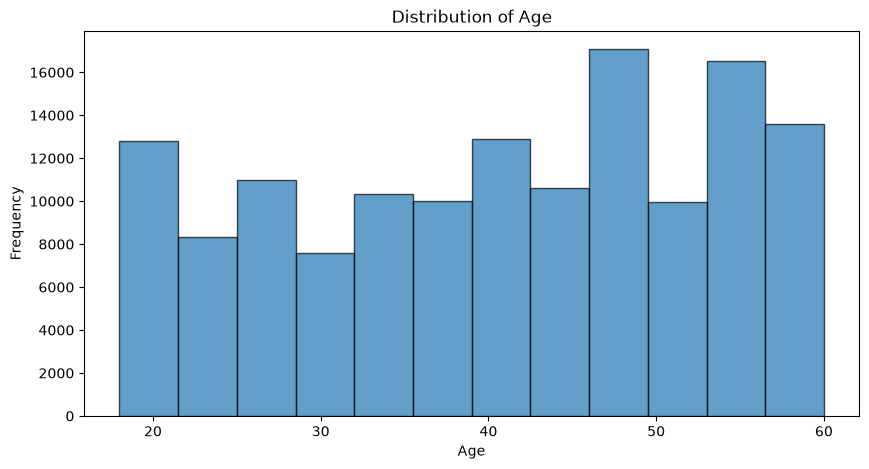

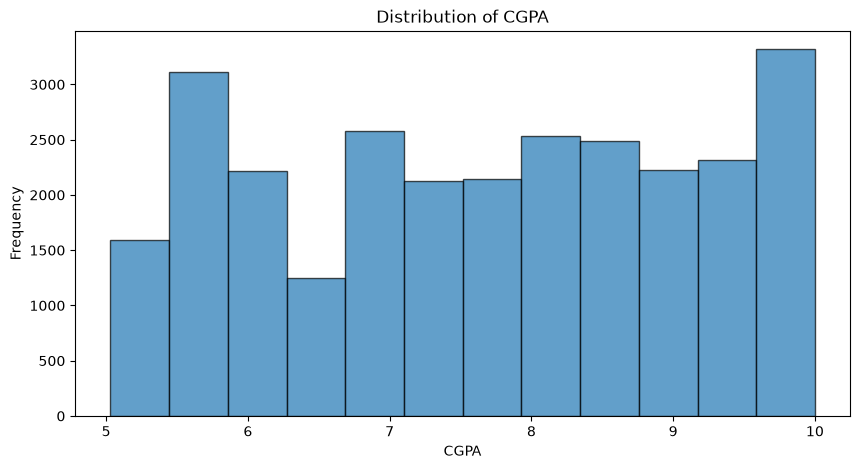

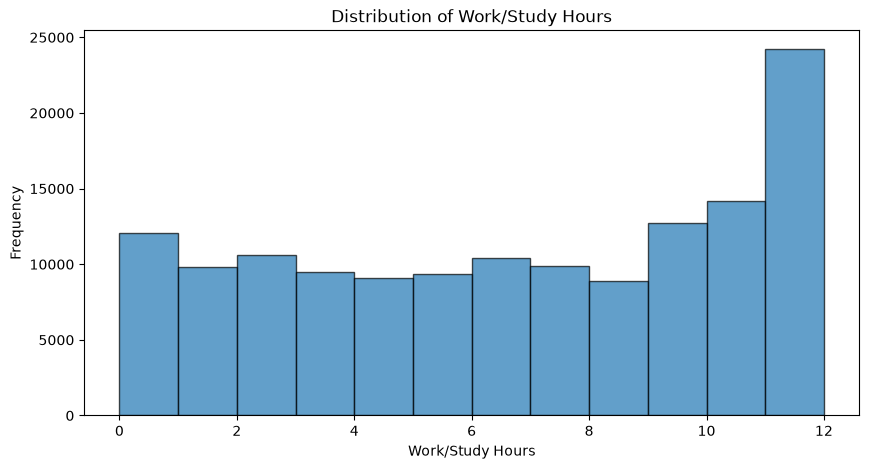

In [16]:
#create graphs compared to the target variable to visualize the data and see if there are any patterns that can be used to predict depression

test_cols = ["City", "Sleep Duration"]
numerical_cols = ["Age", "CGPA", "Work/Study Hours"]
categorical_cols = ["Gender", "City", "Working Professional or Student", "Profession", "Academic Pressure", 
                    "Work Pressure", "Study Satisfaction", "Job Satisfaction", "Sleep Duration", "Dietary Habits", "Degree", 
                    "Have you ever had suicidal thoughts ?", "Financial Stress", "Family History of Mental Illness"]

# Categorical variables
for col in categorical_cols:
    fig, ax = plt.subplots(figsize=(10, 5))

    depression_rate = df.groupby(col)["Depression"].mean()
    depression_rate.plot(kind="bar", ax=ax)

    ax.set_title(f"Depression vs {col}")
    ax.set_ylabel("Mean Depression Rate")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# Numerical variables
for col in numerical_cols:
    plt.figure(figsize=(10, 5))

    values = df[col].dropna()
    plt.hist(values, bins=12, edgecolor="black", alpha=0.7)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

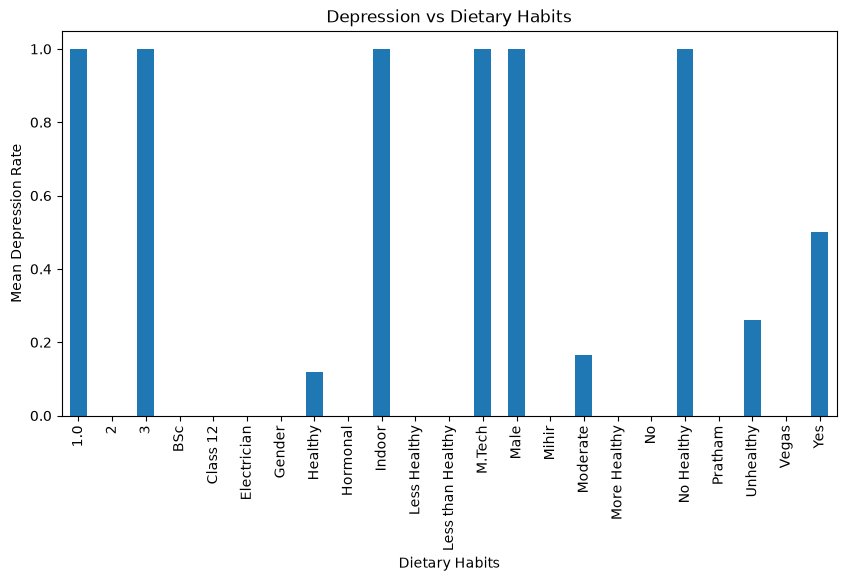

In [14]:
#graph dietary habits vs depression on its own 

plt.figure(figsize=(10, 5))
dietary_depression_rate = df.groupby("Dietary Habits")["Depression"].mean()
dietary_depression_rate.plot(kind="bar")
plt.title("Depression vs Dietary Habits")
plt.ylabel("Mean Depression Rate")
plt.xlabel("Dietary Habits")    
plt.show()

In [22]:

# find all rows where the profession matches the name 
print(df[df["Profession"] == df["Name"]].iloc[:, 1:7])

print(df[df["Profession"] == "Yogesh"].iloc[:, 1:7])

                  Name  Gender   Age         City  \
12526           Yogesh    Male  34.0       Indore   
28927           Yogesh    Male  33.0         Agra   
63149       Researcher  Female  60.0       Jaipur   
64786          Plumber  Female  27.0  Vasai-Virar   
92096   UX/UI Designer  Female  44.0       Rajkot   
129275          Yuvraj    Male  43.0    Ahmedabad   

       Working Professional or Student      Profession  
12526             Working Professional          Yogesh  
28927             Working Professional          Yogesh  
63149             Working Professional      Researcher  
64786             Working Professional         Plumber  
92096             Working Professional  UX/UI Designer  
129275            Working Professional          Yuvraj  
         Name Gender   Age      City Working Professional or Student  \
12526  Yogesh   Male  34.0    Indore            Working Professional   
28927  Yogesh   Male  33.0      Agra            Working Professional   
44829  Yuvraj

In [26]:
# print the first couple rows of the testing dataset
df_Test["Depression"] = np.nan #add the target variable to the test dataset for consistency
df_Test.head(5)

,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,140700,Shivam,Male,53.0,Visakhapatnam,Working Professional,Judge,NaN,2.0,NaN,NaN,5.0,Less than 5 hours,Moderate,LLB,No,9.0,3.0,Yes,NaN
1,140701,Sanya,Female,58.0,Kolkata,Working Professional,Educational Consultant,NaN,2.0,NaN,NaN,4.0,Less than 5 hours,Moderate,B.Ed,No,6.0,4.0,No,NaN
2,140702,Yash,Male,53.0,Jaipur,Working Professional,Teacher,NaN,4.0,NaN,NaN,1.0,7-8 hours,Moderate,B.Arch,Yes,12.0,4.0,No,NaN
3,140703,Nalini,Female,23.0,Rajkot,Student,NaN,5.0,NaN,6.84,1.0,NaN,More than 8 hours,Moderate,BSc,Yes,10.0,4.0,No,NaN
4,140704,Shaurya,Male,47.0,Kalyan,Working Professional,Teacher,NaN,5.0,NaN,NaN,5.0,7-8 hours,Moderate,BCA,Yes,3.0,4.0,No,NaN


In [34]:
# for var in varNames:
#     print(f"{var}: {(df[var].isna().sum())} null values",)

# is likely that academic/work pressure are nan when they are not applicable, so we will fill those with 0
# test to see if this is true first

for _ in ["Academic Pressure", "Work Pressure"]:
    print(f"{_}: {(df[df[_].isna() & (df['Working Professional or Student'] == 'Student')].shape[0])} null values for students")
    print(f"{_}: {(df[df[_].isna() & (df['Working Professional or Student'] == 'Working Professional')].shape[0])} null values for working professionals")

#print num of working professionals
print(f"\nNumber of working professionals: {(df[df['Working Professional or Student'] == 'Working Professional'].shape[0])}")
print(f"Number of students: {(df[df['Working Professional or Student'] == 'Student'].shape[0])}")

Academic Pressure: 9 null values for students
Academic Pressure: 112794 null values for working professionals
Work Pressure: 27898 null values for students
Work Pressure: 20 null values for working professionals

Number of working professionals: 112799
Number of students: 27901


In [46]:
#find the students who wrote down a value for work pressure 
students_with_WP = (df[df["Work Pressure"].notna() & (df['Working Professional or Student'] == 'Student')])
print("Students with a value for work pressure:")
print(f"{students_with_WP.iloc[:, :4]}")
print(f"{students_with_WP["Depression"]}")


#find the working professionals who wrote down a value for academic pressure
workers_with_AP = (df[df["Academic Pressure"].notna() & (df['Working Professional or Student'] == 'Working Professional')])
print("\nWorking professionals with a value for academic pressure:")
print(f"{workers_with_AP.iloc[:, :4]}")
print(f"{workers_with_AP["Depression"]}")

Students with a value for work pressure:
            id    Name Gender   Age
21880    21880  Aarush   Male  38.0
75007    75007   Aarav   Male  21.0
129756  129756    Kian   Male  18.0
21880     0
75007     0
129756    1
Name: Depression, dtype: int64

Working professionals with a value for academic pressure:
            id     Name  Gender   Age
18752    18752    Aarti  Female  18.0
41915    41915   Advait    Male  18.0
55827    55827   Prachi  Female  19.0
99062    99062  Tanisha  Female  24.0
101189  101189   Keshav    Male  34.0
18752     1
41915     1
55827     1
99062     1
101189    0
Name: Depression, dtype: int64
